In [1]:
#Assignment 2: Testing data analysis skills with pandas, numpy, and matplotlib. Use the dataset from the zip file.
#Total points: 24

#You are allowed to seek help from your classmates; however, it should be your own work.
#You can not copy or paste their work. If you seek help, you need to acknowledge it in your submission.
#You will submit the commented and outputs-printed Jupyter Notebook file

#Remove all unnecessary code and outputs.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix #You may or may not need

# Light, recessive grid so the data stands out in every chart
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

# Consistent colors used across the charts
BLUE, ORANGE, GREEN = '#2a78d6', '#eb6834', '#1baf7a'

# Wider printed tables so they don't wrap
pd.set_option('display.width', 150)

In [3]:
df = pd.read_csv("used_device_data.csv")
df.head()

,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


In [4]:
#Question 1: Report any data limitations. Your response must be generated using Python code; do not calculate or analyze this manually. (1 point)

# 1) Size of the dataset
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

# 2) Missing values per column (count and %)
missing = pd.DataFrame({'missing': df.isnull().sum(),
                        '% missing': (df.isnull().mean() * 100).round(2)})
print("\n--- Missing values ---")
print(missing[missing['missing'] > 0].sort_values('missing', ascending=False))
print(f"Rows with at least one missing value: {df.isnull().any(axis=1).sum()}")

# 3) Duplicate rows
print(f"\n--- Duplicate rows: {df.duplicated().sum()} ---")

# 4) Skewness of numeric columns (|skew| > 1 = highly skewed, the mean is pulled by extreme values)
print("\n--- Skewness of numeric columns ---")
print(df.select_dtypes(include='number').skew().round(2).sort_values(ascending=False))

# 5) Imbalanced categories
for col in ['os', '5g']:
    print(f"\n--- Share of devices by {col} (%) ---")
    print((df[col].value_counts(normalize=True) * 100).round(1))
print(f"\nDevices with brand recorded only as 'Others': {(df['device_brand'] == 'Others').sum()} "
      f"({(df['device_brand'] == 'Others').mean() * 100:.1f}%)")

# 6) Time coverage and range of device types
print(f"\nRelease years covered: {df['release_year'].min()} to {df['release_year'].max()}")
print(f"Screen size range: {df['screen_size'].min()} to {df['screen_size'].max()} cm | "
      f"Weight range: {df['weight'].min()} to {df['weight'].max()} g")

# 7) Suspicious / implausible values
print(f"\nDevices with less than 1 GB of internal memory: {(df['internal_memory'] < 1).sum()}")
suspicious = df[(df['release_year'] <= 2014) & (df['screen_size'] < 8) & (df['internal_memory'] >= 128)]
print(f"Small-screen (< 8 cm) devices from 2013-2014 listed with 128 GB or more: {len(suspicious)}")

# 8) Metadata vs. actual column names
metadata_cols = ['device_brand', 'os', 'screen_size', '4g', '5g', 'front_camera_mp', 'back_camera_mp',
                 'internal_memory', 'ram', 'battery', 'weight', 'release_year', 'days_used',
                 'normalized_new_price', 'normalized_used_price']
print(f"\nIn metadata but not in the data: {sorted(set(metadata_cols) - set(df.columns))}")
print(f"In the data but not in the metadata: {sorted(set(df.columns) - set(metadata_cols))}")

Rows: 3,454 | Columns: 15

--- Missing values ---
                 missing  % missing
rear_camera_mp       179       5.18
weight                 7       0.20
battery                6       0.17
internal_memory        4       0.12
ram                    4       0.12
front_camera_mp        2       0.06
Rows with at least one missing value: 201

--- Duplicate rows: 0 ---

--- Skewness of numeric columns ---
internal_memory          5.79
weight                   3.23
front_camera_mp          1.80
battery                  1.33
ram                      1.07
screen_size              1.02
rear_camera_mp           0.77
release_year             0.32
normalized_new_price    -0.08
days_used               -0.34
normalized_used_price   -0.53
dtype: float64

--- Share of devices by os (%) ---
os
Android    93.1
Others      4.0
Windows     1.9
iOS         1.0
Name: proportion, dtype: float64

--- Share of devices by 5g (%) ---
5g
no     95.6
yes     4.4
Name: proportion, dtype: float64

Devices with b

**Data limitations (Question 1):**

1. **Missing values.** `rear_camera_mp` is missing for 179 devices (5.2%), and a few values are missing in `weight` (7), `battery` (6), `internal_memory` (4), `ram` (4) and `front_camera_mp` (2). Any analysis that uses these columns has to drop or fill those rows (the regression in Q8 uses 3,437 of 3,454 rows).
2. **Highly skewed variables.** `internal_memory` (skew 5.8), `weight` (3.2), `front_camera_mp` (1.8), `battery`, `ram` and `screen_size` are strongly right-skewed, so their means are pulled up by a few extreme devices and medians describe a "typical" device better.
3. **Imbalanced categories.** About 93% of devices run Android and only 4.4% (152 devices) have 5G; iOS has only 36 devices. Conclusions about 5G, iOS or Windows devices rest on small groups.
4. **Vague brand information.** 502 devices (14.5%) have the brand recorded only as "Others", so brand effects cannot be fully analyzed.
5. **Old and mixed devices.** The data only covers models released 2013–2020, and it mixes small feature phones (5 cm screens) with tablets (up to 30.7 cm and 855 g), so it may not represent today's used-phone market.
6. **Suspicious values.** 45 small-screen devices from 2013–2014 are listed with 128 GB or more of internal memory, which is implausible for phones of that era; these were probably recorded in MB instead of GB (e.g., 512 MB = 0.5 GB). At the other extreme, 42 devices have less than 1 GB.
7. **Unclear price scale.** Prices are "normalized" but the metadata does not say how (currency, log scale, etc.), so results can be compared relatively but not translated into dollars.
8. **Metadata errors.** The metadata lists `back_camera_mp`, but the column in the data is `rear_camera_mp`, and the descriptions of the front and rear cameras are swapped. The data also has no information on the condition of each device (scratches, battery health), which surely affects used prices.

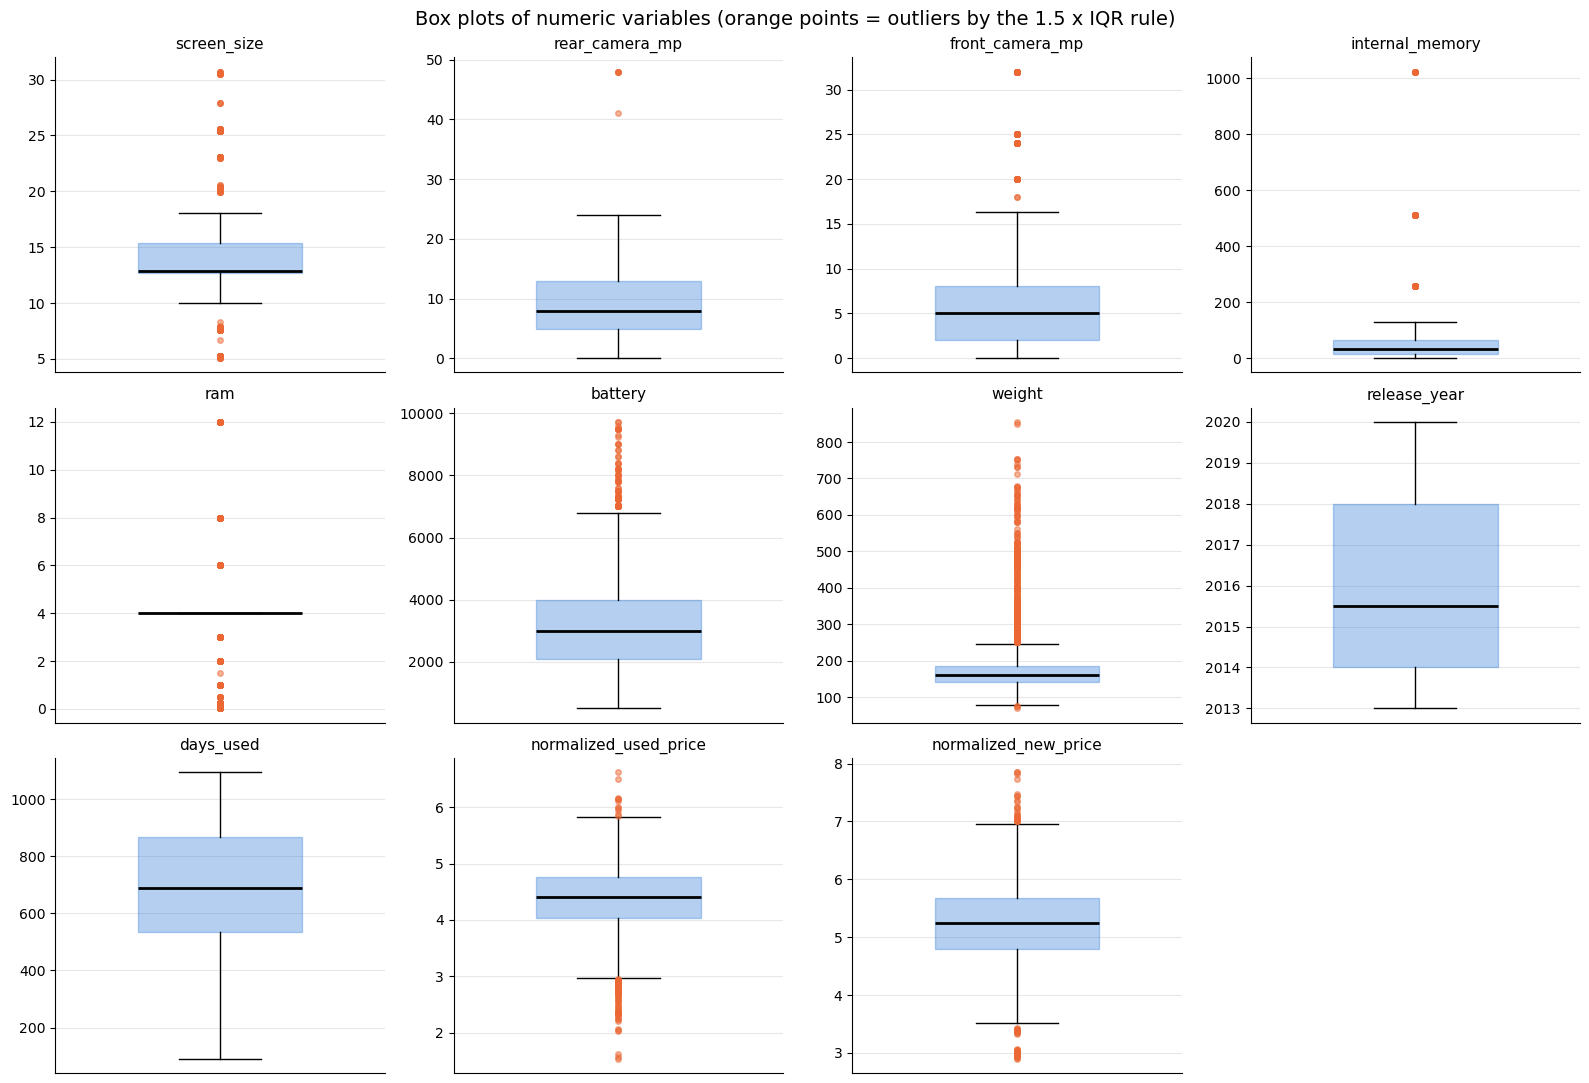

Number of outliers per variable (1.5 x IQR rule):
ram                      635
screen_size              450
weight                   368
front_camera_mp          221
internal_memory          138
normalized_used_price     85
battery                   77
normalized_new_price      66
rear_camera_mp             5
release_year               0
days_used                  0
dtype: int64


In [5]:
#Question 2: Comment on outliers using visualization. (2 points)

num_cols = df.select_dtypes(include='number').columns

# One box plot per numeric variable (each has its own scale). Points beyond the whiskers are outliers (1.5 x IQR rule)
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    ax.boxplot(df[col].dropna(), widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=BLUE, alpha=0.35, color=BLUE),
               medianprops=dict(color='black', linewidth=2),
               flierprops=dict(marker='o', markersize=4, markerfacecolor=ORANGE, markeredgecolor=ORANGE, alpha=0.5))
    ax.set_title(col, fontsize=11)
    ax.set_xticks([])
for ax in axes[len(num_cols):]:
    ax.axis('off')
fig.suptitle('Box plots of numeric variables (orange points = outliers by the 1.5 x IQR rule)', fontsize=14)
plt.tight_layout()
plt.show()

# Count the outliers shown in the box plots to support the visual
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
outlier_counts = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
print("Number of outliers per variable (1.5 x IQR rule):")
print(outlier_counts.sort_values(ascending=False))

**Comments on outliers (Question 2):**

- **`weight` (368), `front_camera_mp` (221), `internal_memory` (138) and `battery` (77)** have outliers only (or almost only) on the high side. Most look like real devices rather than errors: tablets explain the heaviest devices (up to 855 g) and the biggest batteries (up to 9,720 mAh), and premium phones explain memory of 512 GB–1 TB.
- **`screen_size` (450)** has outliers on both sides: small feature phones (~5 cm) at the bottom and tablets (up to 30.7 cm) at the top, showing that the data mixes very different types of devices.
- **`ram` (635)** has the most outliers, but this is a side effect of the rule: 81% of devices have exactly 4 GB, so the box collapses into a line and every device with a different amount of RAM is flagged.
- **`normalized_used_price` (85) and `normalized_new_price` (66)** have outliers on both sides, mostly on the low side (very cheap, old basic phones), with a few flagship devices at the top.
- **`days_used` and `release_year` have no outliers**; their values are spread evenly within a fixed range.
- **Implication:** outliers are concentrated in skewed variables, so medians are more reliable than means for those columns. Outliers should be investigated rather than deleted automatically, since most represent genuinely different devices (tablets, flagships, feature phones).

In [6]:
#Question 3: Create a new column device_age that represents the age of the device in years. Print the mean device age. (1 point)

from datetime import date

current_year = date.today().year                      # age is measured up to the current year
df['device_age'] = current_year - df['release_year']  # years since the model was released

print(f"Mean device age: {df['device_age'].mean():.2f} years (as of {current_year})")

Mean device age: 10.03 years (as of 2026)


In [7]:
#Question 4: Now, start using numpy functions to generate insights from the data
#Question 4a: Calculate the average, minimum, and maximum values of days_used using numpy and print them.  (1 point)

days_used = df['days_used'].to_numpy()

print(f"Average days_used: {np.mean(days_used):.2f} days")
print(f"Minimum days_used: {np.min(days_used)} days")
print(f"Maximum days_used: {np.max(days_used)} days")

Average days_used: 674.87 days
Minimum days_used: 91 days
Maximum days_used: 1094 days


In [8]:
#Question 4b: Calculate and print standard deviation and variance of normalized_used_price. (1 point)

used_price = df['normalized_used_price'].to_numpy()

print(f"Standard deviation of normalized_used_price: {np.std(used_price):.4f}")
print(f"Variance of normalized_used_price: {np.var(used_price):.4f}")

Standard deviation of normalized_used_price: 0.5888
Variance of normalized_used_price: 0.3467


In [9]:
#Question 4c: Calculate the 25th, 50th, and 75th percentiles of normalized_new_price and normalized_used_price. (1 point)

new_price = df['normalized_new_price'].to_numpy()

percentiles = pd.DataFrame({'normalized_new_price': np.percentile(new_price, [25, 50, 75]),
                            'normalized_used_price': np.percentile(used_price, [25, 50, 75])},
                           index=['25th percentile', '50th percentile (median)', '75th percentile'])
print(percentiles.round(4))

                          normalized_new_price  normalized_used_price
25th percentile                         4.7903                 4.0339
50th percentile (median)                5.2459                 4.4051
75th percentile                         5.6737                 4.7557


**Comment (4c):** at every percentile, the used price is about 0.76–0.92 normalized units below the new price (the gap grows slightly for more expensive devices), so used devices consistently sell below the price of the same model new.

In [10]:
#Question 4d: Count the number of devices in the data that have a normalized used price of less than 4.5. (1 point)

below_4_5 = np.sum(used_price < 4.5)
print(f"Devices with normalized_used_price < 4.5: {below_4_5} ({below_4_5 / len(used_price) * 100:.1f}% of all devices)")

Devices with normalized_used_price < 4.5: 2001 (57.9% of all devices)


In [11]:
#Question 5: We often deal with massive datasets. In such cases, sampling is a useful approach.
#Randomly sample 500 devices from the dataset and calculate the average normalized_used_price and print. (1 point)

sample = df.sample(n=500, random_state=42)   # random_state makes the sample reproducible

print(f"Average normalized_used_price (sample of 500): {sample['normalized_used_price'].mean():.4f}")
print(f"Average normalized_used_price (all {len(df):,} devices): {df['normalized_used_price'].mean():.4f}")

Average normalized_used_price (sample of 500): 4.3970
Average normalized_used_price (all 3,454 devices): 4.3647


**Comment (Q5):** the sample mean (about 4.40) is very close to the mean of the full dataset (about 4.36), so a random sample of only 500 devices (~14% of the data) gives a good estimate of the overall average.

In [12]:
#Question 7a: Calculate the z-scores of normalized_used_price to identify outliers.
#You can use 3 standard deviations to identify outliers.
#Print the number of outliers. (2 points)

# z = (value - mean) / standard deviation
df['z_used_price'] = (used_price - np.mean(used_price)) / np.std(used_price)

is_outlier = np.abs(df['z_used_price']) > 3
print(f"Number of outliers (|z| > 3): {is_outlier.sum()}")
print(f"  High-price outliers (z > 3):  {(df['z_used_price'] > 3).sum()}")
print(f"  Low-price outliers (z < -3):  {(df['z_used_price'] < -3).sum()}")

Number of outliers (|z| > 3): 35
  High-price outliers (z > 3):  5
  Low-price outliers (z < -3):  30


In [13]:
# Question 7b: Continuing from 7a, you are now interested to know why these are outliers.
    #You think that days_used, internal_memory, and weight could be the reasons.
#Compare these three variables of your outliers and the whole data and print them. Comment on your results.
#Hint: Create a separate dataframe (subset) for the outliers. (3 points)

compare_cols = ['days_used', 'internal_memory', 'weight']

# Subset of outliers, also split into low-price and high-price outliers
outliers = df[np.abs(df['z_used_price']) > 3]
low_outliers = outliers[outliers['z_used_price'] < 0]
high_outliers = outliers[outliers['z_used_price'] > 0]

groups = {'Whole data': df, 'All outliers': outliers,
          'Low-price outliers': low_outliers, 'High-price outliers': high_outliers}

mean_comparison = pd.DataFrame({name: g[compare_cols].mean() for name, g in groups.items()}).round(1)
median_comparison = pd.DataFrame({name: g[compare_cols].median() for name, g in groups.items()}).round(1)

print("Number of devices:", {name: len(g) for name, g in groups.items()})
print("\nMEAN values:")
print(mean_comparison.T)
print("\nMEDIAN values:")
print(median_comparison.T)

Number of devices: {'Whole data': 3454, 'All outliers': 35, 'Low-price outliers': 30, 'High-price outliers': 5}

MEAN values:
                     days_used  internal_memory  weight
Whole data               674.9             54.6   182.8
All outliers             680.0            177.5   140.7
Low-price outliers       726.8            108.6   116.7
High-price outliers      398.8            563.2   284.2

MEDIAN values:
                     days_used  internal_memory  weight
Whole data               690.5             32.0   160.0
All outliers             687.0            128.0   140.0
Low-price outliers       752.5             48.0    95.8
High-price outliers      478.0            512.0   241.0


**Comments (Question 7b):**

- **The 35 outliers are really two different groups:** 30 are unusually *cheap* devices and 5 are unusually *expensive* ones. Averaging them together hides the story (for example, the "all outliers" mean for days used, ~680, is almost the same as the whole data), so I compared each group with the whole data separately.
- **`days_used` plays a small role.** Low-price outliers were used somewhat longer than a typical device (median ~753 vs. ~691 days, about two extra months), while high-price outliers were used much less (median ~478 days, mean ~399), consistent with them being recent flagship models. The difference for the cheap devices is small compared with how far their price is from the average, so usage time alone does not explain them.
- **`internal_memory` explains the high-price outliers.** The expensive outliers have a median of 512 GB vs. 32 GB for the whole data. Surprisingly, the cheap outliers also have *more* memory than the typical device (median 48 GB, mean ~109 GB). This comes from old 2013–2014 feature phones listed with 128–256 GB, the implausible values flagged in Q1 (probably MB recorded as GB). So memory cannot explain the cheap outliers; instead it reveals a data-quality problem.
- **`weight` helps explain both groups.** Low-price outliers are much lighter (median ~96 g vs. 160 g), typical of small basic phones, while high-price outliers are heavier (median ~241 g, mean ~284 g), typical of large-screen flagships and tablets.
- **Conclusion:** the outliers are driven mainly by the *type of device* (small, basic phones vs. large premium devices), which shows up in weight and, for the expensive group, in memory. Days used contributes only a little. Variables not tested here, such as release year and 5G, probably matter as well: the cheap outliers are mostly 2013–2014 models, and the expensive ones are 2018–2020 models.

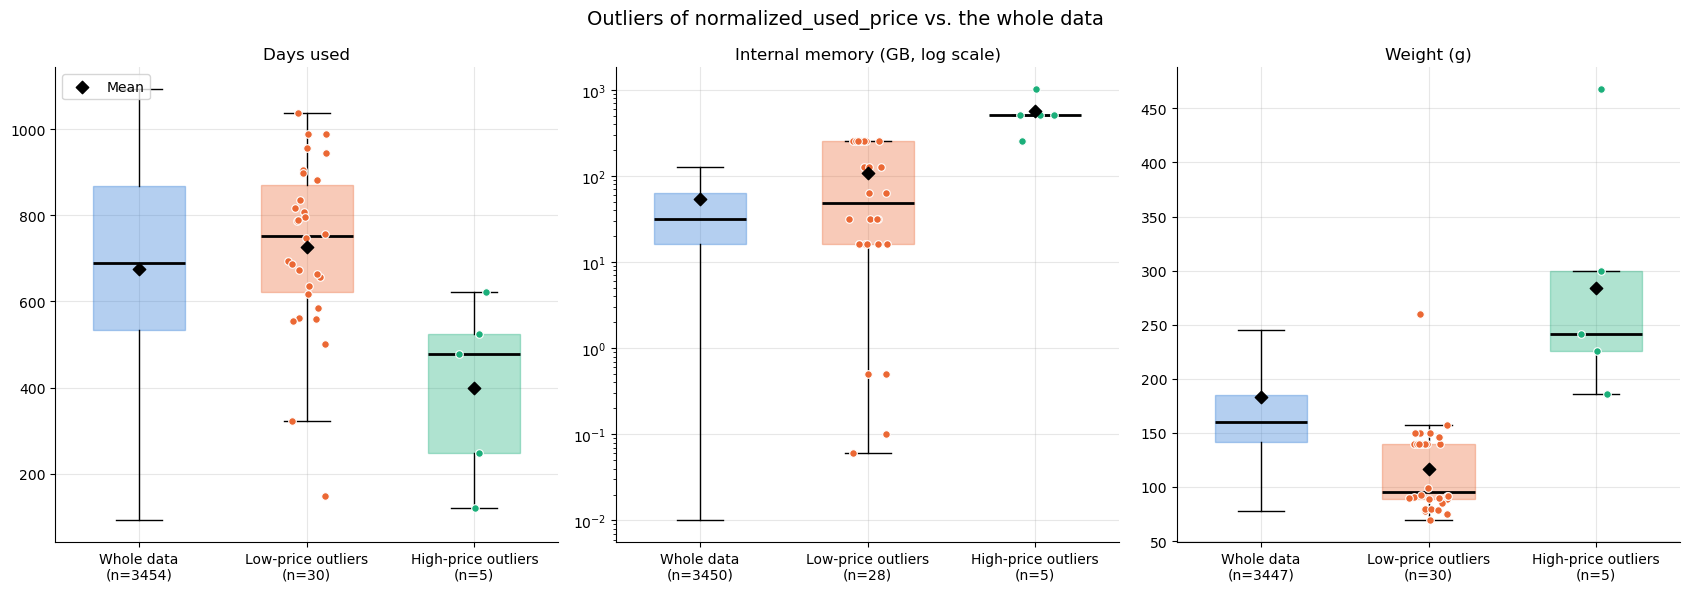

In [14]:
#Question 7c: Plot these comparions. You can choose the chart that you think will be more appropriate for visualization. (3 points)

# Box plots are used because these variables are skewed: they show the median and the full spread,
# while a bar chart of means would be distorted by a few extreme values.
group_names = ['Whole data', 'Low-price outliers', 'High-price outliers']
group_data = [df, low_outliers, high_outliers]
colors = [BLUE, ORANGE, GREEN]
labels = {'days_used': 'Days used', 'internal_memory': 'Internal memory (GB, log scale)', 'weight': 'Weight (g)'}

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, col in zip(axes, compare_cols):
    data = [g[col].dropna() for g in group_data]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color='black', linewidth=2))
    for patch, c in zip(bp['boxes'], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.35)
        patch.set_edgecolor(c)
    # Overlay the individual outlier devices (few points, so each one is visible)
    rng = np.random.default_rng(1)
    for i, (d, c) in enumerate(zip(data[1:], colors[1:]), start=2):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, color=c, s=30, edgecolor='white', linewidth=0.8, zorder=3)
    # Mark the mean of each group with a diamond
    ax.scatter(range(1, 4), [d.mean() for d in data], marker='D', color='black', s=40, zorder=4, label='Mean')
    ax.set_xticks(range(1, 4))
    ax.set_xticklabels([f"{n}\n(n={len(d)})" for n, d in zip(group_names, data)])
    ax.set_title(labels[col], fontsize=12)
    if col == 'internal_memory':
        ax.set_yscale('log')
axes[0].legend(loc='upper left')
fig.suptitle('Outliers of normalized_used_price vs. the whole data', fontsize=14)
plt.tight_layout()
plt.show()

**Comments (Question 7c):** box plots were chosen because these variables are skewed, so the median and the spread are more informative than a bar of means (the diamond still marks each mean). The charts confirm 7b: for *days used*, the low-price outliers overlap heavily with the whole data, while the high-price outliers sit lower. *Internal memory* (log scale) clearly separates the high-price outliers (all between 256 GB and 1 TB), while the cheap outliers are spread from under 1 GB up to 256 GB. *Weight* separates both groups best: cheap outliers sit below the typical device and expensive outliers sit above it.

In [15]:
#Continue Case 2 with stattsmodels

In [16]:
#Question 8: Create a multiple linear regression model using the following independent variables
#internal_memory, battery, weight, days_used, 5g_yes
#Your dependent variable is normalized_used_price
#Explain the coefficients properly (4 points)

import statsmodels.api as sm

# Dummy variable: 5g_yes = 1 if the device has 5G, 0 otherwise
df['5g_yes'] = (df['5g'] == 'yes').astype(int)

predictors = ['internal_memory', 'battery', 'weight', 'days_used', '5g_yes']
model_df = df[predictors + ['normalized_used_price']].dropna()   # drop the few rows with missing values

X = sm.add_constant(model_df[predictors])   # add the intercept
y = model_df['normalized_used_price']

model = sm.OLS(y, X).fit()
print(model.summary())

# Coefficients in more practical units (coefficient x a meaningful change)
units = {'internal_memory': (100, '+100 GB of memory'), 'battery': (1000, '+1,000 mAh of battery'),
         'weight': (100, '+100 g of weight'), 'days_used': (365, '+1 year (365 days) of use'),
         '5g_yes': (1, 'having 5G vs. not')}
effects = pd.DataFrame({'change': [units[p][1] for p in predictors],
                        'coefficient': [model.params[p] for p in predictors],
                        'effect on used price': [model.params[p] * units[p][0] for p in predictors],
                        'p-value': [model.pvalues[p] for p in predictors]}, index=predictors)
print("\nEffect of a practical change in each variable (holding the others constant):")
print(effects.round({'coefficient': 6, 'effect on used price': 4, 'p-value': 4}))
print(f"\nCorrelation between battery and weight: {model_df['battery'].corr(model_df['weight']):.2f}")

                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.424
Model:                               OLS   Adj. R-squared:                  0.424
Method:                    Least Squares   F-statistic:                     506.0
Date:                   Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                           10:44:29   Log-Likelihood:                -2089.1
No. Observations:                   3437   AIC:                             4190.
Df Residuals:                       3431   BIC:                             4227.
Df Model:                              5                                         
Covariance Type:               nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const       

**Explanation of the coefficients (Question 8):**

Each coefficient is the expected change in `normalized_used_price` for a one-unit increase in that variable, **holding the other four variables constant**.

- **Intercept (const = 3.696):** the predicted normalized used price for a device with 0 GB memory, 0 mAh battery, 0 g weight, 0 days of use and no 5G. No real device looks like that, so it has no practical meaning; it is the starting point of the regression line.
- **internal_memory (0.00044, p < 0.001):** each additional GB of internal memory raises the predicted used price by 0.00044 units; **100 GB more adds about 0.044**. Positive and statistically significant, but a small effect.
- **battery (0.00026, p < 0.001):** each additional mAh raises the predicted used price by 0.00026; **1,000 mAh more adds about 0.255**. It has the largest t-statistic (27.5), making it the strongest and most reliable predictor in the model.
- **weight (−0.00022, p = 0.080):** each additional gram lowers the predicted used price by 0.00022 (100 g ≈ −0.022). This is **not statistically significant at the 5% level**. On its own, weight is positively related to price, but weight is highly correlated with battery (r = 0.70): heavier devices are heavy mostly *because* they have bigger batteries and screens. Once battery is held constant, extra weight adds no value.
- **days_used (−0.00020, p < 0.001):** each additional day of use lowers the predicted used price by 0.00020; **one year of use lowers it by about 0.071**. Significant and negative, as expected: more wear means a lower resale value.
- **5g_yes (0.4406, p < 0.001):** a device with 5G is predicted to sell for **0.44 units more** than an otherwise similar device without 5G. This is the largest single effect in the model.
- **Model fit:** R² = 0.424, so these five variables explain about 42% of the variation in used prices. The remaining 58% comes from factors not in the model (brand, RAM, cameras, release year, condition, new price).
- **Note on the price scale:** if the normalized price is a log of the actual price (common for this dataset, though the metadata does not confirm it), coefficients can be read as approximate percentages: 5G ≈ +55% (e^0.44 − 1) and one year of use ≈ −7%.
- **Note on the warning:** the large condition number in the summary mostly reflects the very different scales of the variables (battery in thousands vs. 5g_yes as 0/1), not a serious multicollinearity problem.

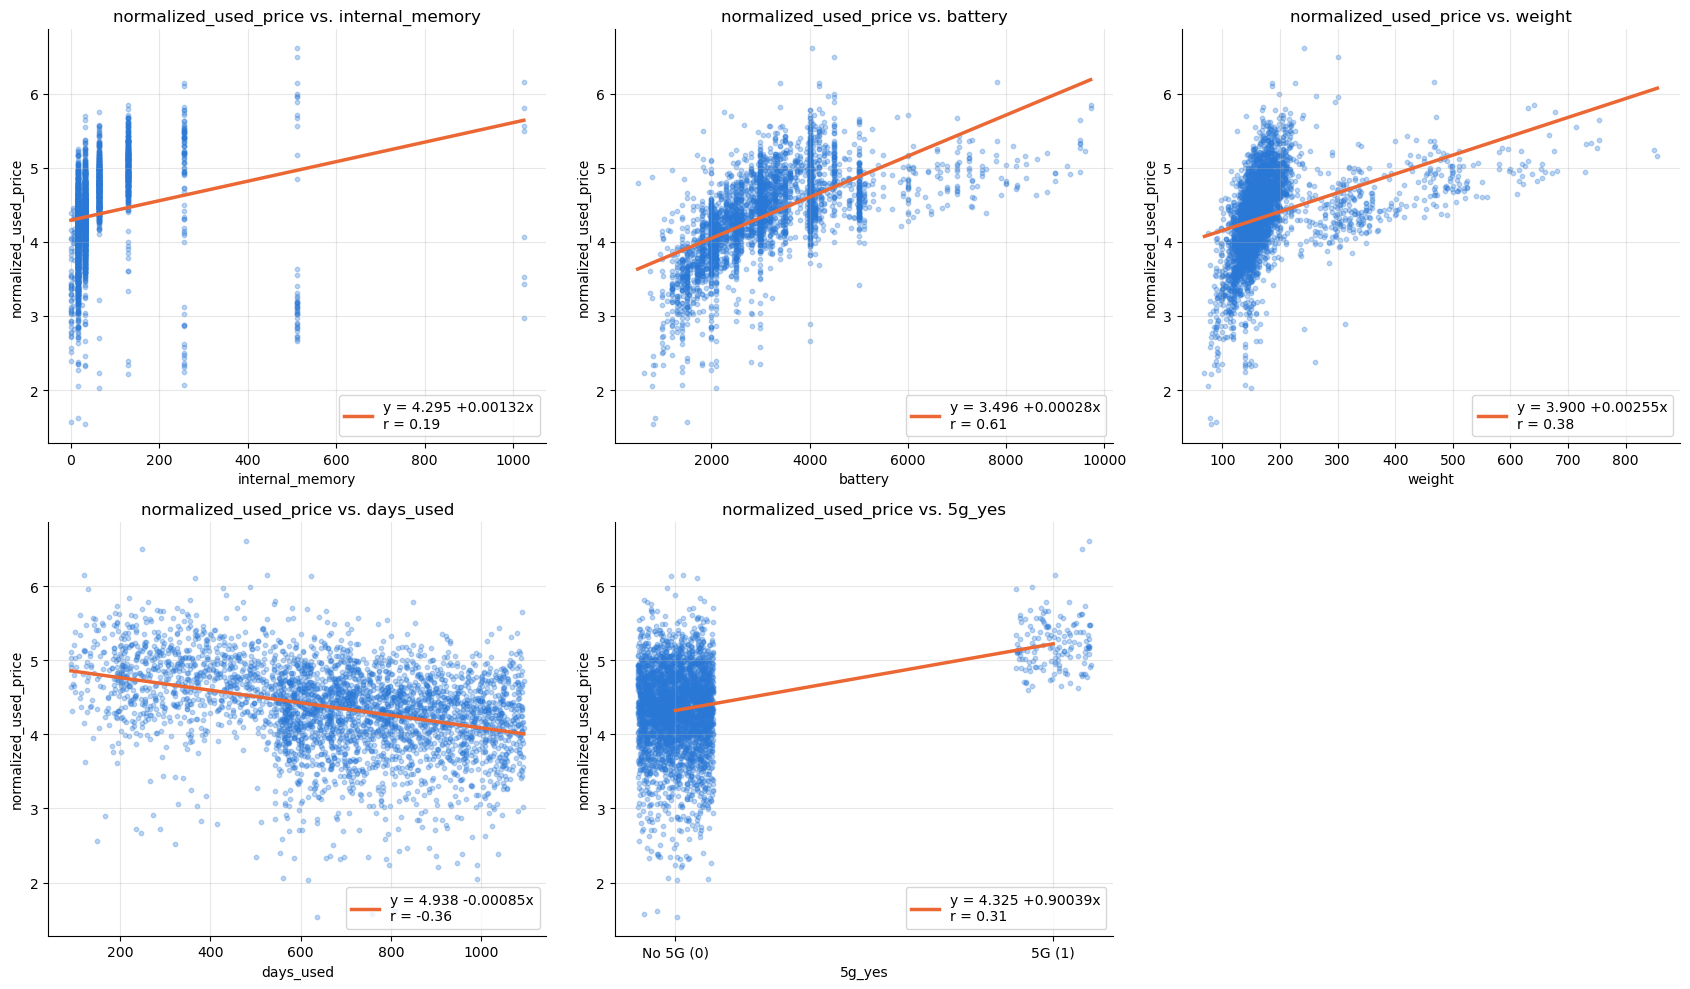

In [17]:
#Question 9:Develop scatterplots of each independent variable with the dependent variable with the regression lines.
# List of predictor variables (2 points)

predictors = ['internal_memory', 'battery', 'weight', 'days_used', '5g_yes']
rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()
for ax, var in zip(axes, predictors):
    data = df[[var, 'normalized_used_price']].dropna()
    x, y_vals = data[var].to_numpy(), data['normalized_used_price'].to_numpy()

    # Simple linear regression line (one predictor at a time)
    slope, intercept = np.polyfit(x, y_vals, 1)
    r = np.corrcoef(x, y_vals)[0, 1]

    # 5g_yes only takes 0 or 1, so add a small horizontal jitter to make the points visible
    x_plot = x + rng.uniform(-0.1, 0.1, len(x)) if var == '5g_yes' else x
    ax.scatter(x_plot, y_vals, s=10, alpha=0.3, color=BLUE)

    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, intercept + slope * x_line, color=ORANGE, linewidth=2.5,
            label=f'y = {intercept:.3f} {slope:+.5f}x\nr = {r:.2f}')
    ax.set_xlabel(var)
    ax.set_ylabel('normalized_used_price')
    ax.set_title(f'normalized_used_price vs. {var}', fontsize=12)
    ax.legend(loc='lower right')
axes[4].set_xticks([0, 1])
axes[4].set_xticklabels(['No 5G (0)', '5G (1)'])
axes[5].axis('off')
plt.tight_layout()
plt.show()

**Comments (Question 9):**

- **battery (r = 0.61)** has the clearest positive linear relationship with used price, consistent with being the strongest predictor in Q8.
- **days_used (r = −0.36)** shows a clear negative slope: devices used longer sell for less.
- **5g_yes (r = 0.31):** the line connects the average price of non-5G and 5G devices. The raw gap here is 0.90, about twice the 0.44 coefficient in Q8, because 5G devices also tend to have bigger batteries and fewer days of use; the multiple regression separates those effects.
- **internal_memory (r = 0.19)** has a weak relationship. Most devices sit at 16–128 GB, and there is a cluster of cheap devices at 256–512 GB (the suspicious old phones from Q1) that weakens the line.
- **weight (r = 0.38)** looks positive here, but its coefficient in Q8 was negative and not significant. The plot shows two clouds: phones (steep relationship) and tablets (flatter). Since heavier devices also have bigger batteries, once battery is held constant in the multiple regression, weight no longer adds value.
- These lines are *simple* regressions (one variable at a time), which is why their slopes differ from the multiple regression coefficients in Q8.